# Simple Linear Regression

We begin with the standard imports:

In [2]:
import matplotlib.pyplot as plt
import numpy as np

We will start with the most familiar linear regression, a straight-line fit to data.
A straight-line fit is a model of the form:
$$
y = ax + b
$$
where $a$ is commonly known as the *slope*, and $b$ is commonly known as the *intercept*.

Consider the following data, which is scattered about a line with a slope of 2 and an intercept of –5 (see the following figure):

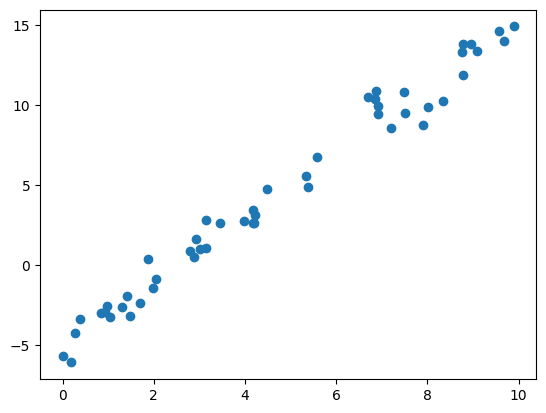

In [3]:
rng = np.random.RandomState(1)
x = 10 * rng.rand(50)
y = 2 * x - 5 + rng.randn(50)
plt.scatter(x, y);

We can use Scikit-Learn's `LinearRegression` estimator to fit this data and construct the best-fit line, as shown in the following figure:

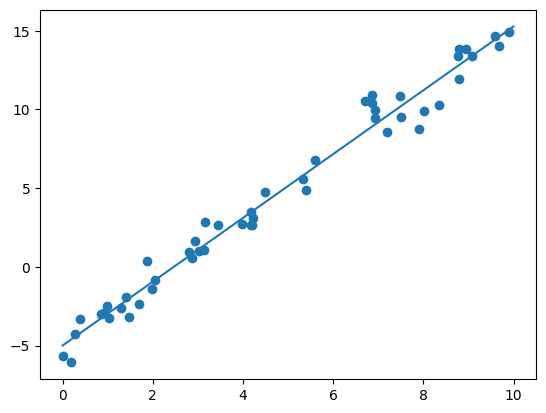

In [4]:
from sklearn.linear_model import LinearRegression
model = LinearRegression(fit_intercept=True)

model.fit(x[:, np.newaxis], y)

xfit = np.linspace(0, 10, 1000)
yfit = model.predict(xfit[:, np.newaxis])

plt.scatter(x, y)
plt.plot(xfit, yfit);

The slope and intercept of the data are contained in the model's fit parameters, which in Scikit-Learn are always marked by a trailing underscore.
Here the relevant parameters are `coef_` and `intercept_`:

In [5]:
print("Model slope:    ", model.coef_[0])
print("Model intercept:", model.intercept_)

Model slope:     2.0272088103606953
Model intercept: -4.998577085553204


We see that the results are very close to the values used to generate the data, as we might hope.

The `LinearRegression` estimator is much more capable than this, however—in addition to simple straight-line fits, it can also handle multidimensional linear models of the form:
$$
y = a_0 + a_1 x_1 + a_2 x_2 + \cdots
$$
where there are multiple $x$ values.
Geometrically, this is akin to fitting a plane to points in three dimensions, or fitting a hyperplane to points in higher dimensions.

The multidimensional nature of such regressions makes them more difficult to visualize, but we can see one of these fits in action by building some example data, using NumPy's matrix multiplication operator:

In [ ]:
rng = np.random.RandomState(1)
X = 10 * rng.rand(100, 3)
y = 0.5 + np.dot(X, [1.5, -2., 1.])

model.fit(X, y)
print(model.intercept_)
print(model.coef_)

0.5000000000000033
[ 1.5 -2.   1. ]


Here the $y$ data is constructed from a linear combination of three random $x$ values, and the linear regression recovers the coefficients used to construct the data.

In this way, we can use the single `LinearRegression` estimator to fit lines, planes, or hyperplanes to our data.

## **Your Turn**
A mechanical engineer is studying the relationship between an applied load and the resulting deflection of a cantilever beam. The beam is fixed at one end, and a vertical load (P) is applied at the free end.

The following experimental measurements were collected:

\begin{array}{c|c}
\text{Load } P \; (\mathrm{N}) & \text{Tip Deflection } \delta \; (\mathrm{mm}) \\
\hline
10 & 0.43 \\
20 & 0.81 \\
30 & 1.25 \\
40 & 1.61 \\
50 & 2.06 \\
60 & 2.42 \\
70 & 2.88 \\
80 & 3.24
\end{array}


You will use simple linear regression to model the relationship between the applied load and the measured beam deflection.

Assume the regression model

$$
\hat{\delta}=\beta_0+\beta_1P,
$$

where $P$ is the applied load, $\hat{\delta}$ is the predicted tip deflection, and $\beta_0$ and $\beta_1$ are parameters to be learned from the experimental data.

### **Tasks**
1.  Visualize the data.
Create a scatter plot of applied load $P$ versus measured tip deflection $\delta$. Based on the plot, does a linear relationship appear reasonable?

2. Fit a linear regression model.
Fit the model below, and report the estimated values of $\beta_0$ and $\beta_1$.

$$
\hat{\delta}=\beta_0+\beta_1P.
$$


3. Visualize the fitted model.
Plot the experimental measurements and the fitted regression line on the same figure.

4. Make a prediction.
Use your fitted model to predict the tip deflection when

$$
P=55\text{ N}.
$$

5. Examine the errors.
For each experimental point, calculate the residual using the equation below.

$$
e_i=\delta_i-\hat{\delta}_i.
$$

6. Following Quesiton 5, plot the residuals as a function of applied load. Do you observe any obvious pattern in the residuals? What does this suggest about the linear model?

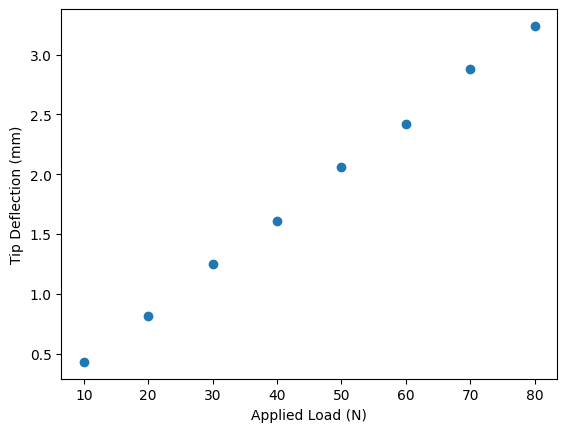

In [8]:
#1 Visualize Data
P = np.array([10, 20, 30, 40, 50, 60, 70, 80])
deflection = np.array([0.43, 0.81, 1.25, 1.61, 2.06, 2.42, 2.88, 3.24])

plt.scatter(P, deflection)
plt.xlabel('Applied Load (N)')
plt.ylabel('Tip Deflection (mm)')
plt.show()


A linear relationship clearly fits here.

beta_0 = 0.017142857142857792
beta_1 = 0.04045238095238095


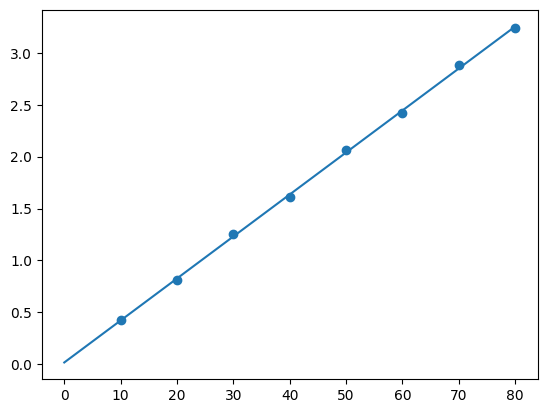

In [14]:
#2/3 Fit LinReg model and Visual
model = LinearRegression(fit_intercept=True)

model.fit(P[:, np.newaxis], deflection)

xfit = np.linspace(0, 80, 8000)
yfit = model.predict(xfit[:, np.newaxis])

# Regression parameters
beta_0 = model.intercept_
beta_1 = model.coef_[0]
print("beta_0 =", beta_0)
print("beta_1 =", beta_1)

plt.scatter(P, deflection)
plt.plot(xfit, yfit);

In [17]:
#4 Prediction off model

P55 = np.array([[55]])
deflection55 = model.predict(P55)

print("55N predicted deflection = ", deflection55[0], "mm")

55N predicted deflection =  2.24202380952381 mm


P = 10 N  Residual = 0.008333333333332693 mm
P = 20 N  Residual = -0.016190476190476755 mm
P = 30 N  Residual = 0.019285714285713684 mm
P = 40 N  Residual = -0.025238095238095726 mm
P = 50 N  Residual = 0.020238095238094722 mm
P = 60 N  Residual = -0.02428571428571491 mm
P = 70 N  Residual = 0.031190476190475547 mm
P = 80 N  Residual = -0.013333333333333641 mm


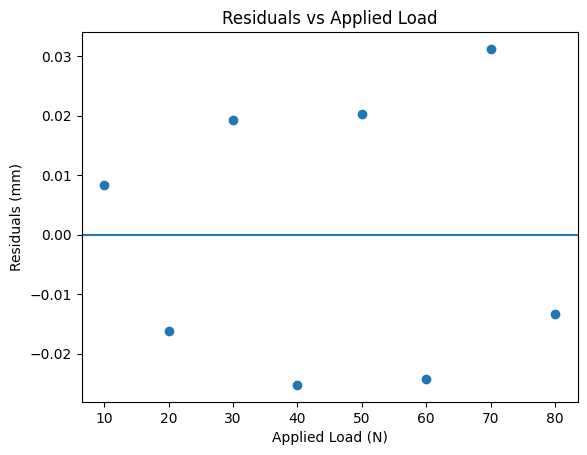

In [18]:
#5/6 Error via residuals

deflection_hat = model.predict(P[:, np.newaxis])
residuals = deflection - deflection_hat

for i in range(len(P)):
    print("P =", P[i], "N",
          " Residual =", residuals[i], "mm")

plt.scatter(P, residuals)
plt.axhline(y=0)

plt.xlabel('Applied Load (N)')
plt.ylabel('Residuals (mm)')
plt.title('Residuals vs Applied Load')

plt.show()

The residuals or error is small and has no discernable pattern or trend. This does not change with increased load. Thus the linear regression model is a good fit for this relationship.
